# ML LAB 8
# Name - Suhani Joshi
# Batch - C_C2
# Roll no - 21

In [45]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)


In [4]:
df = pd.read_csv("Wholesale customers data.csv")

In [5]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [6]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [7]:
df.shape


(440, 8)

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [73]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [74]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [75]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
435,False
436,False
437,False
438,False


In [76]:
df.drop_duplicates()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


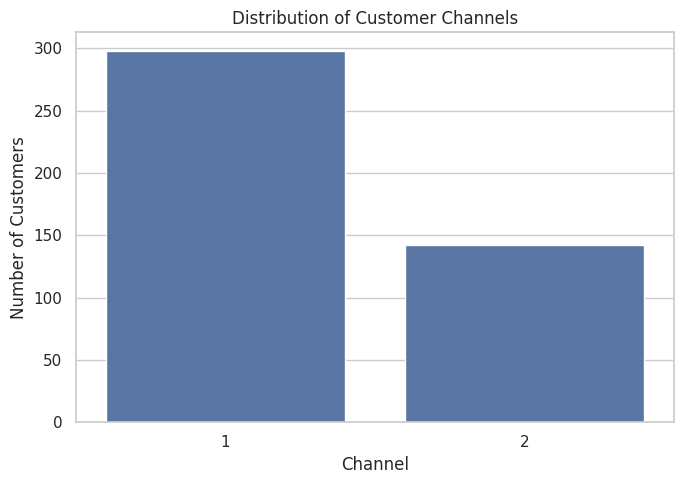

In [77]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Channel")

plt.title("Distribution of Customer Channels")
plt.xlabel("Channel")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


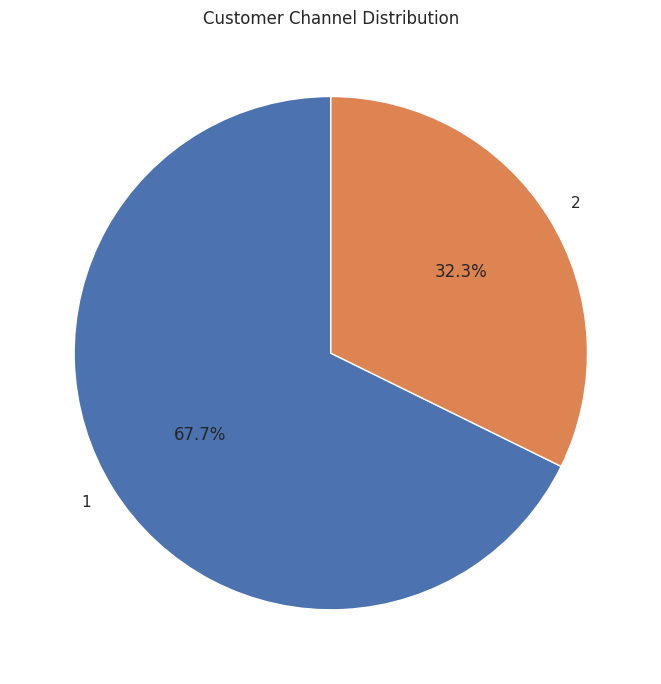

In [78]:
class_counts = df["Channel"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Customer Channel Distribution")
plt.tight_layout()
plt.show()

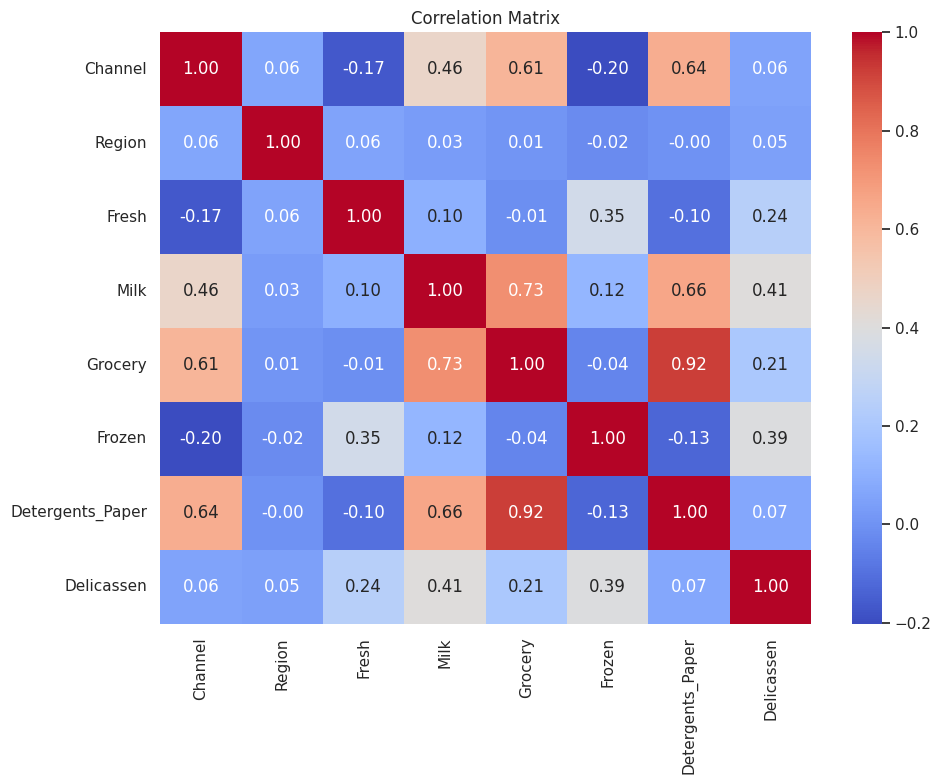

In [79]:
numerical_features = df.select_dtypes(include=np.number).columns

correlation_matrix = df[numerical_features].corr()


plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

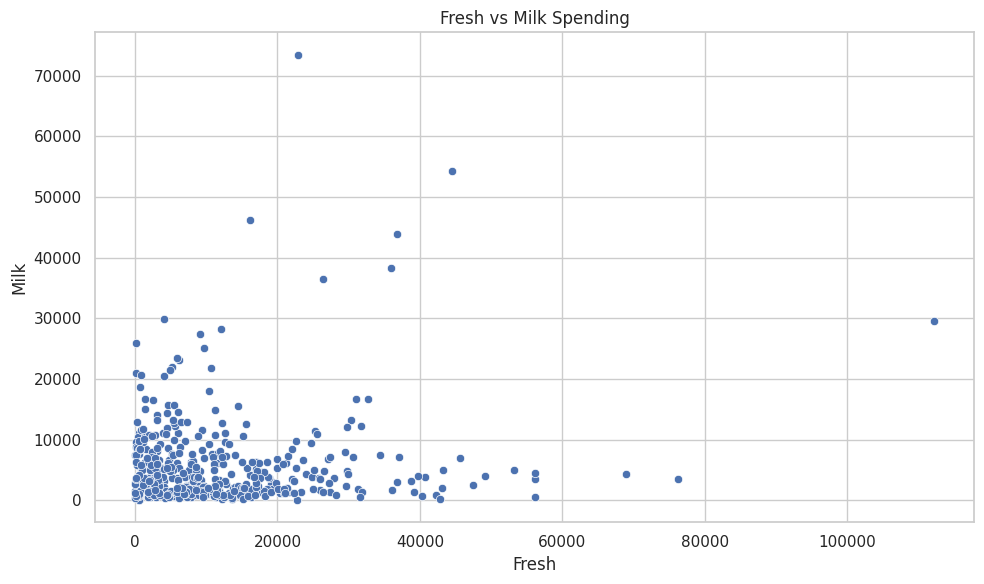

In [80]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="Fresh", y="Milk")

plt.title("Fresh vs Milk Spending")
plt.xlabel("Fresh")
plt.ylabel("Milk")
plt.tight_layout()
plt.show()

In [81]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["Channel_encoded"] = label_encoder.fit_transform(df["Channel"])

print(df[["Channel", "Channel_encoded"]].head(70))

    Channel  Channel_encoded
0         2                1
1         2                1
2         2                1
3         1                0
4         2                1
..      ...              ...
65        2                1
66        1                0
67        2                1
68        1                0
69        1                0

[70 rows x 2 columns]


In [69]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [21]:
features = df.columns

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df.index
)

X_scaled_df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [22]:
display(X_scaled_df.head())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [23]:
print("\n Scaled feature means(appropriate zero):")
print(X_scaled_df.mean().round(3))


 Scaled feature means(appropriate zero):
Channel             0.0
Region              0.0
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [24]:
print("\n Scaled feature standard deviations(appropriate 1):")
print(X_scaled_df.std(ddof=0).round(3))


 Scaled feature standard deviations(appropriate 1):
Channel             1.0
Region              1.0
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


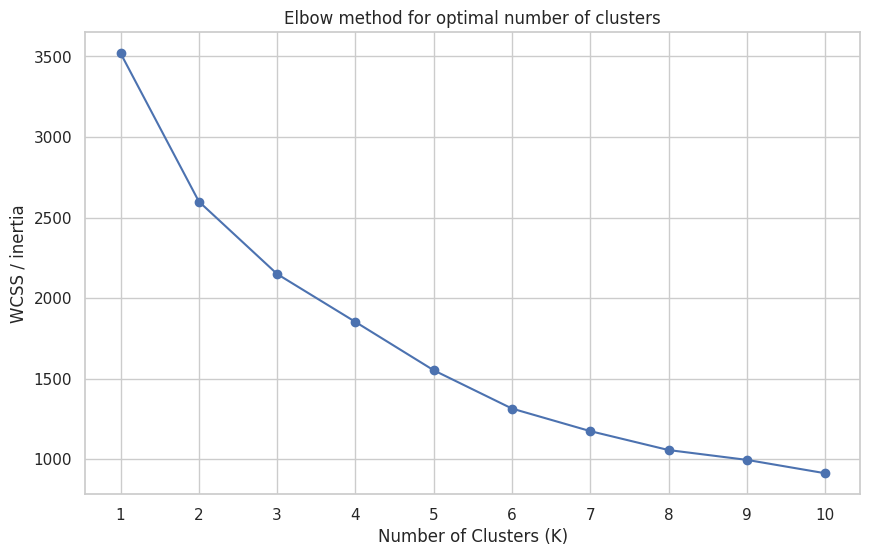

In [25]:
wccs = []
K_values = range (1,11)
for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42,n_init=10)
    kmeans.fit(X_scaled_df)
    wccs.append(kmeans.inertia_)



plt.figure(figsize=(10, 6))
plt.plot(list(K_values), wccs, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.title("Elbow method for optimal number of clusters")
plt.ylabel('WCSS / inertia')
plt.grid(True)
plt.xticks(list(K_values))
plt.show()


In [27]:
silhouette_values = []
for k in range(2,11):
   model = KMeans(n_clusters=k, random_state=42, n_init=10)
   labels = model.fit_predict(X_scaled_df)
   score = silhouette_score(X_scaled_df, labels)
   silhouette_values.append(score)



silhouette_table = pd.DataFrame({'Number of Clusters': range(2,11),
                                 'Silhouette Score': silhouette_values})
display(silhouette_table.round(4))


,Number of Clusters,Silhouette Score
0,2,0.3734
1,3,0.3568
2,4,0.3482
3,5,0.3529
4,6,0.3526
5,7,0.3638
6,8,0.3743
7,9,0.3081
8,10,0.3310


In [28]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['Silhouette Score'].idxmax(), 'Number of Clusters']
)

print("k suggested by highest silhouette score:", suggested_k)

k suggested by highest silhouette score: 8


In [29]:
k = suggested_k

Kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
Kmeans_labels = Kmeans_model.fit_predict(X_scaled)

In [59]:

kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)

kMeans_labels = kmeans_model.fit_predict(X_scaled)

print("KMeans labels created successfully!")

KMeans labels created successfully!


In [60]:
df_Kmeans = df.copy()
df_Kmeans['Kmeans_Cluster'] = kMeans_labels

print("KMeans clustering completed")
print("\nNumber of customers in each cluster:")
print(df_Kmeans["Kmeans_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels:")
display(df_Kmeans.head())

KMeans clustering completed

Number of customers in each cluster:
Kmeans_Cluster
0    201
1     92
2     37
3     61
4      2
5      5
6      1
7     41
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Kmeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


In [43]:
hierarchial_model = AgglomerativeClustering(
    n_clusters=k,
    metric='euclidean',
    linkage='ward'
)

hierarchial_labels = hierarchial_model.fit_predict(X_scaled)

In [41]:
df_hierarchial = df.copy()
df_hierarchial['hierarchial_Cluster'] = hierarchial_labels

print("hierarchial clustering completed")
print("\n Number of customers in each cluster:")
print(df_hierarchial["hierarchial_Cluster"].value_counts().sort_index())

print("\n Sample records with cluster labels:")
display(df_hierarchial.head())

hierarchial clustering completed

 Number of customers in each cluster:
hierarchial_Cluster
0    205
1      5
2     13
3      2
4     78
5     40
6     96
7      1
Name: count, dtype: int64

 Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,hierarchial_Cluster
0,2,3,12669,9656,7561,214,2674,1338,6
1,2,3,7057,9810,9568,1762,3293,1776,6
2,2,3,6353,8808,7684,2405,3516,7844,6
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,6


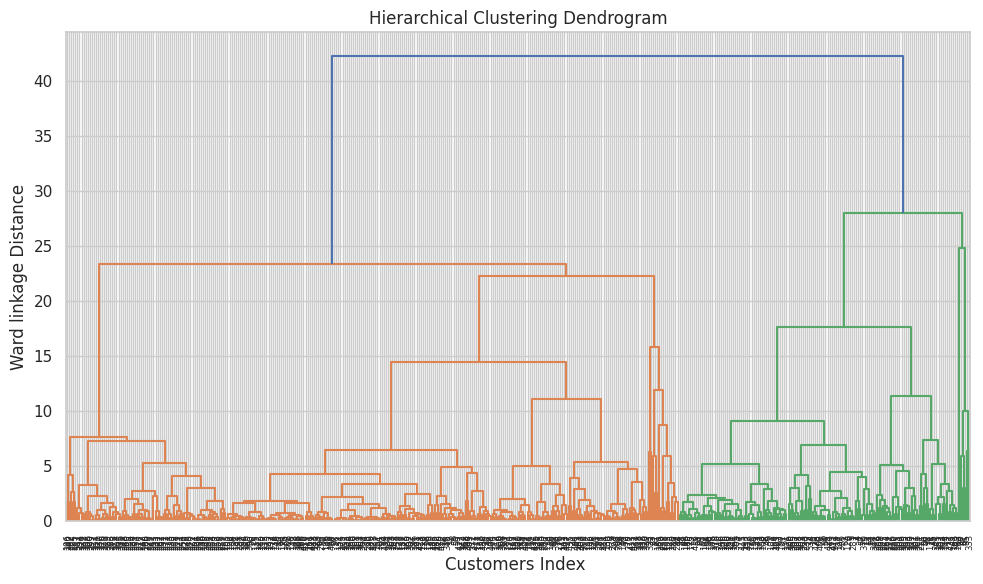

In [46]:
Z = linkage(X_scaled_df, method='ward', metric='euclidean')

plt.figure(figsize=(10, 6))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customers Index ')
plt.ylabel('Ward linkage Distance')
plt.tight_layout()

plt.show()

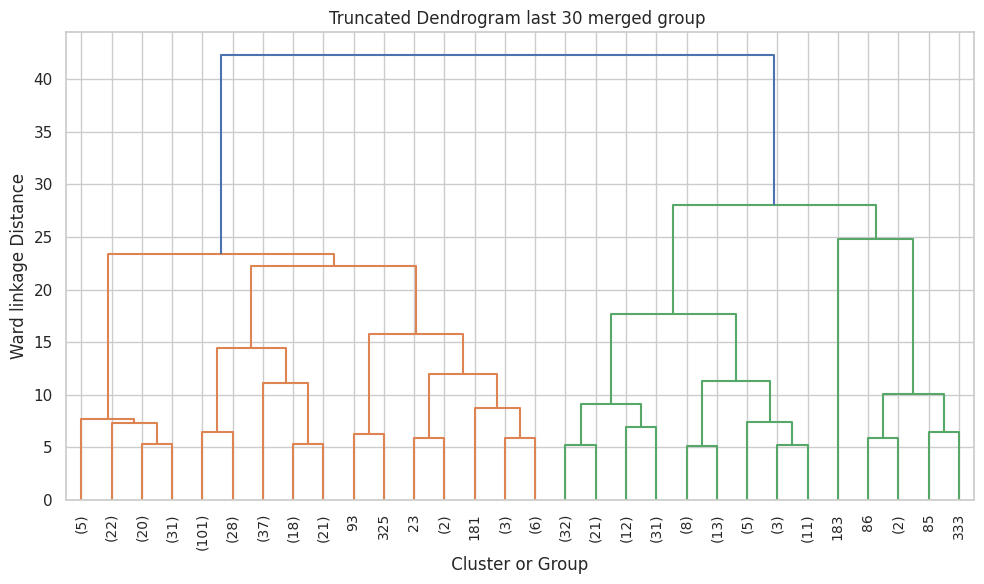

In [51]:
plt.figure(figsize=(10, 6))
dendrogram(Z, truncate_mode = "lastp", p=30, leaf_rotation=90, show_leaf_counts= True)

plt.title("Truncated Dendrogram last 30 merged group ")
plt.xlabel(" Cluster or Group ")
plt.ylabel('Ward linkage Distance')
plt.tight_layout()

plt.show()

In [62]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() *100, 2),
    "%"
)

plot_df = pd.DataFrame({"PC1": X_pca[:,0], "PC2": X_pca[:,1],
                      "Kmeans_Cluster": kMeans_labels.astype(str),
                      "Hierarchial_Cluster": hierarchial_labels.astype(str)
                      })


Variance explained by two PCA components: 61.12 %


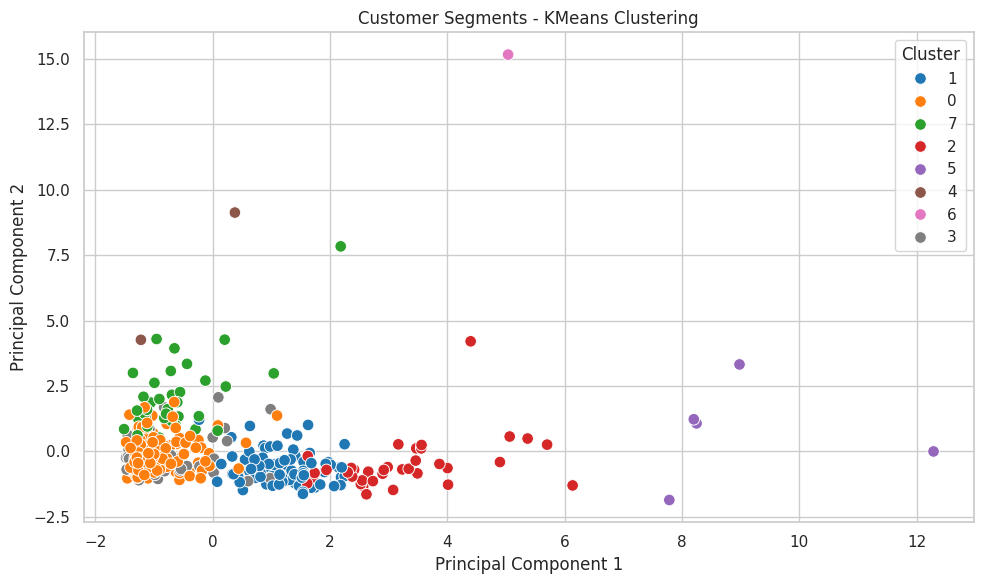

In [64]:

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kMeans_labels.astype(str)
})


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=70
)

plt.title("Customer Segments - KMeans Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [65]:
def evaluate_clustering(X_data, labels, model_name):
  return{
      "Algorithm": model_name,
      "No of clusters ": len(np.unique(labels)),
      "Silhouette Score": silhouette_score(X_data, labels)
  }




In [71]:
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kMeans_labels, "KMeans"),
    evaluate_clustering(X_scaled, hierarchial_labels, "Hierarchical Clustering")
])

print("Comparison of clustering algorithms:")
display(comparison.round(4))

Comparison of clustering algorithms:


,Algorithm,No of clusters,Silhouette Score
0,KMeans,8,0.3743
1,Hierarchical Clustering,8,0.3541
